In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
%cd ..

c:\Users\manuel.deluzi\OneDrive - Havas\Projects\personali\taxi_drivers_lab


In [3]:
import pandas as pd
import numpy as np

class DataFrameProfiler:
    """
    Una suite per estrarre meta-descrizioni complete e statistiche avanzate 
    da un DataFrame di Pandas.
    """
    
    @staticmethod
    def meta_description(df: pd.DataFrame) -> pd.DataFrame:
        """
        Genera un report dettagliato colonna per colonna con tipi di dati,
        valori nulli, unicità, occupazione di memoria e un campione del primo valore valido.
        """
        if not isinstance(df, pd.DataFrame):
            raise TypeError("L'input deve essere un DataFrame di Pandas.")
            
        meta_info = []
        total_rows = len(df)
        
        for col in df.columns:
            col_data = df[col]
            null_count = col_data.isnull().sum()
            null_pct = (null_count / total_rows) * 100 if total_rows > 0 else 0
            unique_count = col_data.nunique()
            
            # Estrazione del primo valore non nullo come campione
            first_valid_index = col_data.first_valid_index()
            sample_value = col_data.loc[first_valid_index] if first_valid_index is not None else np.nan
            
            # Formattazione delle date per una lettura pulita nel report
            if isinstance(sample_value, pd.Timestamp):
                sample_value = sample_value.strftime('%Y-%m-%d %H:%M:%S')
            
            # Calcolo memoria reale (inclusi oggetti complessi/stringhe)
            try:
                memory_kb = col_data.memory_usage(deep=True, index=False) / 1024
            except Exception:
                memory_kb = np.nan
                
            meta_info.append({
                "Colonna": col,
                "Tipo Dato": str(col_data.dtype),
                "Record Totali": total_rows,
                "Valori Non-Nulli": total_rows - null_count,
                "Mancanti (%)": f"{null_pct:.2f}%",
                "Valori Unici": unique_count,
                "Memoria (KB)": round(memory_kb, 2) if not np.isnan(memory_kb) else "N/D",
                "Campione Valore": sample_value
            })
            
        return pd.DataFrame(meta_info)

    @staticmethod
    def general_summary(df: pd.DataFrame):
        """
        Stampa un riepilogo generale della struttura del DataFrame.
        """
        total_memory = df.memory_usage(deep=True).sum() / (1024 ** 2) # In MB
        print("=" * 50)
        print("📊 RIEPILOGO GENERALE DEL DATAFRAME")
        print("=" * 50)
        print(f"Dimensioni globali   : {df.shape[0]} righe x {df.shape[1]} colonne")
        print(f"Duplicati totali     : {df.duplicated().sum()} righe duplicate")
        print(f"Memoria totale (MB)  : {total_memory:.2f} MB")
        print("-" * 50)
        print("Distribuzione Tipi di Dato:")
        print(df.dtypes.value_counts().to_string())
        print("=" * 50)

# ==========================================
# ESEMPIO DI UTILIZZO
# ==========================================
# if __name__ == "__main__":
#     # Creazione di un DataFrame di test (con un valore nullo sulla prima riga di 'Acquisti')
#     data = {
#         'ID_Utente':,
#         'Nome': ['Alice', 'Bob', 'Charlie', 'Alice', None],
#         'Acquisti': [np.nan, 250.50, 15.00, 420.00, 89.90], # Primo valore nullo per testare la robustezza
#         'Data_Iscrizione': pd.to_datetime(['2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04', '2026-01-05']),
#         'Attivo': [True, False, True, True, False]
#     }
#     df_test = pd.DataFrame(data)

#     # Esecuzione
#     DataFrameProfiler.general_summary(df_test)
#     df_meta = DataFrameProfiler.meta_description(df_test)
    
#     print("\n📋 META-DESCRIZIONE DETTAGLIATA CON CAMPIONE:")
#     print(df_meta.to_string(index=False))

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

def genera_wordcloud_categorie(df, colonna_categorie, background_color='white', colormap='Dark2'):
    """
    Genera e mostra una Word Cloud a partire da una colonna di categorie separate da virgole.
    Risolve il KeyError interno disattivando le collocations.
    """
    # 1. Unisce tutte le righe della colonna usando la virgola come separatore
    testo_unito = ", ".join(df[colonna_categorie].dropna().astype(str))
    
    # 2. Configura e genera la Word Cloud con collocations=False e la regex corretta
    wordcloud = WordCloud(
        width=1000, 
        height=500, 
        background_color=background_color,
        colormap=colormap,
        prefer_horizontal=0.7,
        regexp=r'[^,]+',      # Cattura l'intero blocco tra le virgole
        collocations=False    # FONDAMENTALE: evita il KeyError su parole con trattini/spazi
    ).generate(testo_unito)
    
    # 3. Mostra il grafico a schermo
    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.tight_layout(pad=0)
    plt.show()


In [5]:
def map_ga4_categories(path: str) -> str:
    """
    Mappa un percorso URL a una categoria di contenuto secondo parole chiave predefinite.

    Args:
        path (str): Il percorso URL da categorizzare. Esempio: "recensioni/netflix-film/in-sala"

    Returns:
        str: Il nome della categoria mappata. Possibili valori includono:
            - "News"
            - "Recensioni"
            - "Recensioni / In Sala"
            - "In Sala"
            - "Cult Movies"
            - "Animazione"
            - "Approfondimento"
            - "Festival di Cinema"
            - "Trailers"
            - "Trailers / In Sala"
            - "Serie TV"
            - "Guide e Film da Vedere"
            - "Speciali e Magazine"
            - "Live Streaming On Demand"
            - "Rubriche"
            - "Interviste"
            - "Anticipazioni" (prioritaria se presente nel path)
            - "Altro" (default se nessuna corrispondenza)

    Note:
        - Se "anticipazioni" è presente nel path, viene restituita la categoria "Anticipazioni".
        - Se la categoria è "Recensioni" o "Trailers" e "in-sala" è nel path, restituisce rispettivamente "Recensioni / In Sala" o "Trailers / In Sala".
        - La funzione analizza il path suddividendolo in sottoparti e controllando l'intersezione con i set di keyword definiti in CATEGORIES.
    """
    subpaths = path.split("/")
    
    if not subpaths:
        return "Altro"

    for category, keywords in CATEGORIES.items():
        for keyword in keywords:
            if keyword in subpaths:
                # Special cases
                if "si-fara" in subpaths:
                    return "Si farà"
                if "serie-tv" in subpaths:
                    return "Serie TV"
                if "anticipazioni" in subpaths:
                    return "Anticipazioni"
                if category == "Recensioni" and "in-sala" in subpaths:
                    return "Recensioni / In Sala"
                if category == "Trailers" and "in-sala" in subpaths:
                    return "Trailers / In Sala"
                return category
    return "Altro"

In [6]:
from data_access.metrics import get_article_daily_performance, get_article_categories

df = get_article_daily_performance(days=30)                    # default
# df = get_article_daily_performance(since="2026-09-01", until="2026-09-05")
# df = get_article_daily_performance(days=90, include_content=False)   # senza excerpt/content_html
# df = get_article_daily_performance(days=90, include_categories=False)


In [7]:
df_meta = DataFrameProfiler.meta_description(df)
print("\n📋 META-DESCRIZIONE DETTAGLIATA:")
print(df_meta.to_string(index=False))
# print(df_meta[["Colonna", "Campione Valore"]].to_string(index=False))


📋 META-DESCRIZIONE DETTAGLIATA:
                 Colonna           Tipo Dato  Record Totali  Valori Non-Nulli Mancanti (%)  Valori Unici  Memoria (KB)                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 

In [8]:
for cat in df['categories'].unique():
    print(cat)

SHORT FILM
Focus Italia
Latest News &amp; Anticipazioni
Interviews
Eventi
CINEMA CONTEMPORANEO
FESTIVAL DI CINEMA
In Sala
Reviews
Approfondimenti, Mubi Film
IN PRIMO PIANO, Magazine
Film da Vedere
Personaggi
Netflix Film
Sky Film
Festival di Roma
Trailers
Euro Balkan Film Festival
Film in Streaming
Videodrhome
Festival del cinema di Porretta Terme
Film in Streaming, Raiplay
Cannes, Magazine
Conversation
Netflix SerieTv
Serie Tv
Film da Vedere, Reviews
Magazine
Netflix SerieTv, Serie Tv
Prime Video SerieTv
Magazine, Netflix Film
Giffoni Film Festival
Prime Video Film
FESTIVAL DI CINEMA, Latest News &amp; Anticipazioni
Anticipazioni
Approfondimenti, Magazine
Anticipazioni, Latest News &amp; Anticipazioni
Latest News &amp; Anticipazioni, Serie Tv
Film in Streaming, Reviews
Magazine, PANORAMA
Biennale del Cinema di Venezia, Reviews
Mubi Film
Raiplay
Cult
Approfondimenti, Guide
Approfondimenti
Festival del cinema di Porretta Terme, Rubriche
Torino Film Festival
Netflix Film, Reviews
HBO MAX

In [9]:
CATEGORIES = {
    "News": {"latest-news", "focus-italia"},
    # "Anticipazioni": {"anticipazioni"},
    "Recensioni": {"review", "approfondimenti", "streaming"},
    "In Sala": {"in-sala"},
    "Cult Movies": {"cult-movie"},
    "Animazione": {"animazione", "animazione/anime"},
    "Approfondimento": {"approfondimento"},
    "Festival di Cinema": {"festival-di-cinema"},
    "Trailers": {"trailers"},
    "Serie TV": {"serie-tv", "netflix-serie-tv", "prime-video-serietv", "sky-serie-tv",
                 "disney-serietv", "paramount-serie-tv", "appletv-serietv", "tim-vision-serie-tv"},
    "Guide e Film da Vedere": {"film-da-vedere"},
    "Speciali e Magazine": {"magazine-2", "taxidrivers-magazine"},
    "Live Streaming On Demand": {"live-streaming-on-demand"},
    "Rubriche": {"rubriche"},
    "Interviste": {"interviews", "interviews-interviews"}
}

df["link_category"] = df["link"].map(map_ga4_categories)
df["link_category"]

0                      Altro
1                       News
2                       News
3                 Interviste
4         Festival di Cinema
                ...         
18639     Festival di Cinema
18640    Speciali e Magazine
18641               Serie TV
18642               Rubriche
18643               Trailers
Name: link_category, Length: 18644, dtype: object

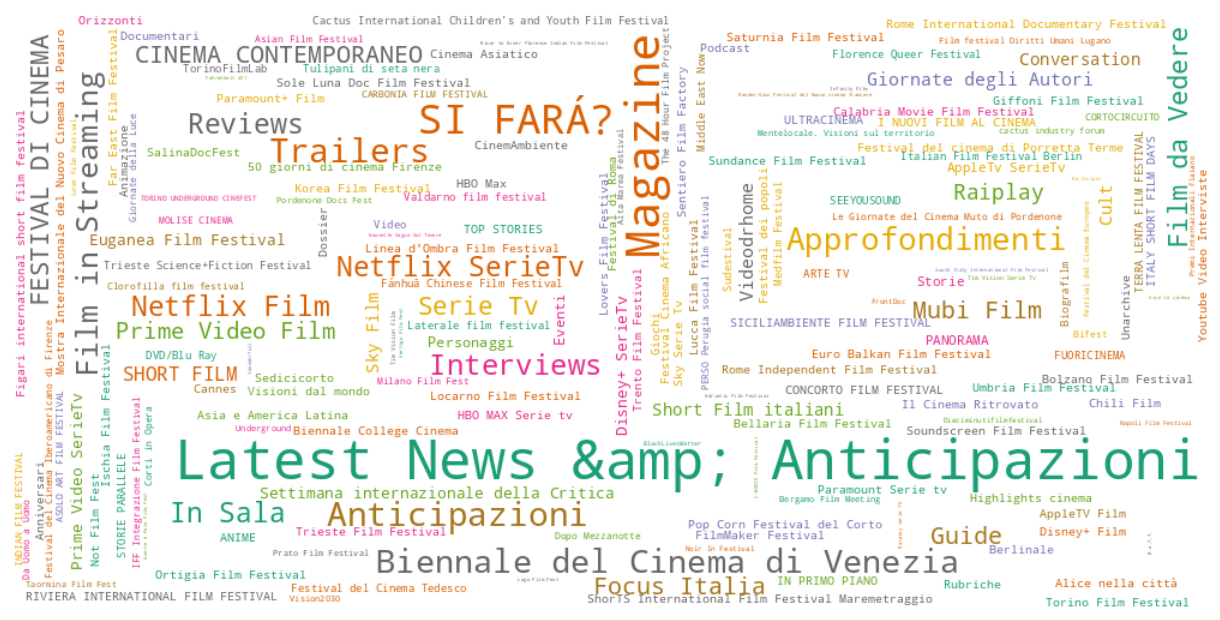

In [10]:
genera_wordcloud_categorie(df, colonna_categorie="categories", background_color='white', colormap='Dark2')

In [11]:
VENEZIA_EVENT = {
    "Biennale del Cinema di Venezia",
    "Orizzonti",
    "Giornate degli Autori",
    "Settimana internazionale della Critica",
    "Biennale College Cinema"
}

cond_venezia = df['categories'].apply(lambda x: any(event in x for event in VENEZIA_EVENT))

df_venezia = df[cond_venezia]

In [12]:
# INTERVISTE_REGEX = "\bInterview(s)?\b|Youtube Video Interviste"

# df_interviste = df[df['categories'].str.contains(INTERVISTE_REGEX, case=False, na=False, regex=True)]

# for link, category in zip(df_interviste["link"], df_interviste["categories"]):
#     print(f"Link: {link} | Categoria: {category}")

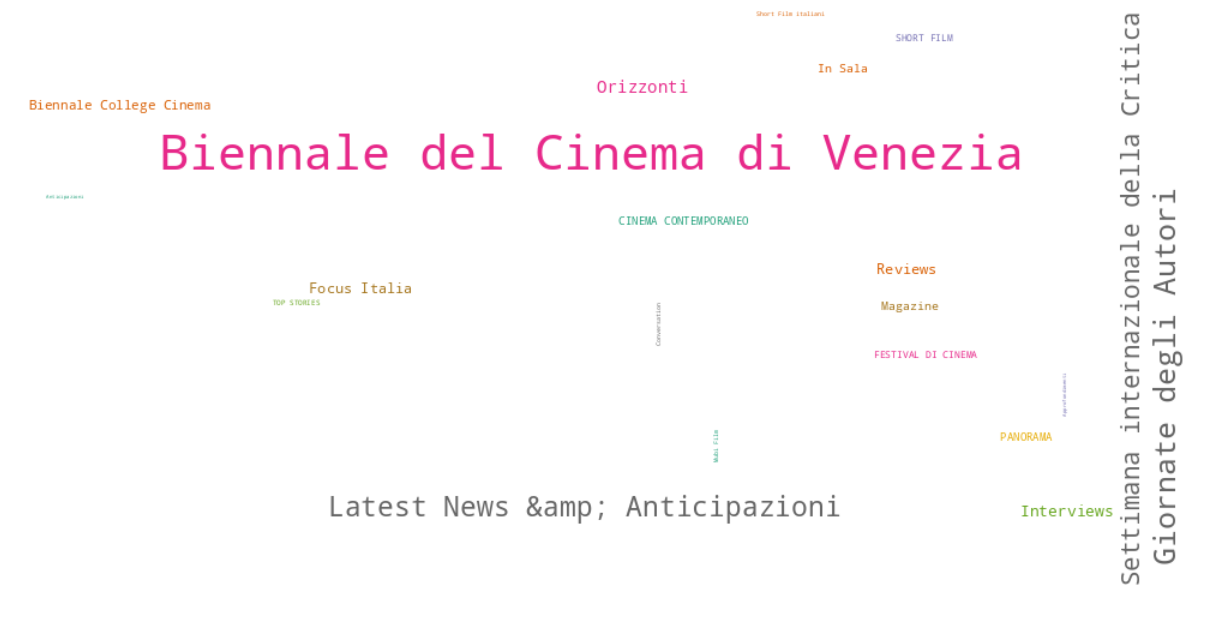

In [13]:
genera_wordcloud_categorie(df_venezia, colonna_categorie="categories", background_color='white', colormap='Dark2')

In [14]:
# 1. Assicurati che la colonna delle date sia in formato datetime
df_venezia['published_at'] = pd.to_datetime(df_venezia['published_at'])

# 3. Definisci la condizione per le date (inclusiva per impostazione predefinita)
cond_data = df_venezia['published_at'].between('2026-08-28', '2026-09-17')

# 4. Applica entrambi i filtri racchiudendoli tra parentesi tonde
df_venezia_filtrato = df_venezia[cond_data]

df_venezia_filtrato.nunique()

C:\Users\manuel.deluzi\AppData\Local\Temp\ipykernel_34244\1943044726.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_venezia['published_at'] = pd.to_datetime(df_venezia['published_at'])


article_id                  165
slug                        165
link                        165
status                        1
title                       165
author_wp_id                 47
author_name                  47
featured_media_url          162
format                        1
comment_status                1
published_at                165
modified_at                 165
excerpt                     165
content_html                165
metric_date                  20
active_users                 37
screen_page_views            45
sessions                     40
engaged_sessions             29
engagement_rate             100
bounce_rate                 101
average_session_duration    810
user_engagement_duration    347
categories                   28
link_category                 7
dtype: int64

In [15]:
import html
import pandas as pd

# ---------------------------------------------------------------------------
# Parametri
# ---------------------------------------------------------------------------

FINESTRA_INIZIO = "2026-08-28"
FINESTRA_FINE = "2026-09-17 23:59:59"

# ---------------------------------------------------------------------------
# 1. Filtro solo sulla finestra temporale, nessun filtro categoria
#    Parte da df_venezia gia' in memoria, non da df grezzo.
# ---------------------------------------------------------------------------

df_venezia["published_at"] = pd.to_datetime(df_venezia["published_at"])
mask_data = df_venezia["published_at"].between(FINESTRA_INIZIO, FINESTRA_FINE)

df_venezia_filtrato = df_venezia[mask_data].copy()

# ---------------------------------------------------------------------------
# 2. Pulizia titoli
# ---------------------------------------------------------------------------

df_venezia_filtrato["title"] = df_venezia_filtrato["title"].apply(html.unescape)

# ---------------------------------------------------------------------------
# 3. Groupby per article_id, somma metriche, anagrafica con first()
# ---------------------------------------------------------------------------

colonne_somma = [
    "screen_page_views",
    "active_users",
    "sessions",
    "engaged_sessions",
    "user_engagement_duration",
]

colonne_anagrafiche = [
    "title",
    "slug",
    "link",
    "author_name",
    "published_at",
    "categories",
    "link_category",
]

df_agg = df_venezia_filtrato.groupby("article_id", as_index=False).agg(
    {
        **{c: "sum" for c in colonne_somma},
        **{c: "first" for c in colonne_anagrafiche},
    }
)

df_agg["engagement_rate"] = (
    df_agg["engaged_sessions"] / df_agg["sessions"]
).fillna(0)
df_agg["average_session_duration"] = (
    df_agg["user_engagement_duration"] / df_agg["sessions"]
).fillna(0)

# ---------------------------------------------------------------------------
# 4. Categorie dinamiche da link_category
#    Un articolo puo' appartenere a piu' categorie nello stesso campo
#    (es. "News, Interviste"): split sulla virgola e pulizia spazi.
#    Se il separatore reale e' diverso, cambiare qui il .split(",").
# ---------------------------------------------------------------------------

categorie_uniche = sorted(
    {
        cat.strip()
        for cell in df_agg["link_category"].dropna()
        for cat in str(cell).split(",")
        if cat.strip()
    }
)

# ---------------------------------------------------------------------------
# 5. Overview per ciascuna categoria trovata
# ---------------------------------------------------------------------------


def calcola_overview(df_categoria: pd.DataFrame) -> dict:
    n_articoli = len(df_categoria)
    n_zero_views = int((df_categoria["screen_page_views"] == 0).sum())
    sessions_tot = df_categoria["sessions"].sum()

    return {
        "n_articoli": n_articoli,
        "views_totali": int(df_categoria["screen_page_views"].sum()),
        "engagement_medio": round(
            df_categoria["engaged_sessions"].sum() / sessions_tot, 3
        ) if sessions_tot > 0 else 0,
        "n_zero_views": n_zero_views,
        "pct_zero_views": round(100 * n_zero_views / n_articoli, 1) if n_articoli else 0,
    }


righe_overview = []
for categoria in categorie_uniche:
    df_cat = df_agg[df_agg["link_category"].apply(lambda c: categoria in str(c))]
    stats = calcola_overview(df_cat)
    righe_overview.append({"categoria": categoria, **stats})

overview_categorie = pd.DataFrame(righe_overview).sort_values(
    "views_totali", ascending=False
).reset_index(drop=True)

df_agg.to_csv("df_venezia_agg.csv", index=False)
overview_categorie.to_csv("overview_categorie.csv", index=False)

C:\Users\manuel.deluzi\AppData\Local\Temp\ipykernel_34244\3248795779.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_venezia["published_at"] = pd.to_datetime(df_venezia["published_at"])


In [16]:
df_venezia

,article_id,slug,link,status,title,author_wp_id,author_name,featured_media_url,format,comment_status,...,active_users,screen_page_views,sessions,engaged_sessions,engagement_rate,bounce_rate,average_session_duration,user_engagement_duration,categories,link_category
139,196582,welcome-venice-la-recensione-del-film-di-andre...,https://www.taxidrivers.it/196582/festival-di-...,publish,&#8216;Welcome Venice&#8217; la recensione del...,172,Carlo Cerofolini,None,standard,open,...,1.0,1.0,1.0,1.0,1.000000,0.000000,14.803250,14.0,"Biennale del Cinema di Venezia, Reviews",Festival di Cinema
271,306681,die-theorie-von-allem-recensione-del-film-piu-...,https://www.taxidrivers.it/306681/festival-di-...,publish,&#8216;Die theorie von Allem&#8217;. Recension...,356,Mattia Calvi,https://www.taxidrivers.it/wp-content/uploads/...,standard,closed,...,1.0,1.0,1.0,0.0,0.000000,1.000000,0.000000,0.0,Biennale del Cinema di Venezia,Festival di Cinema
375,391510,i-film-piu-apprezzati-nella-storia-del-festiva...,https://www.taxidrivers.it/391510/panorama/i-f...,publish,I film più apprezzati nella storia della Mostr...,191,Sandra Orlando,https://www.taxidrivers.it/wp-content/uploads/...,standard,closed,...,0.0,0.0,1.0,0.0,0.000000,1.000000,0.000000,0.0,"Biennale del Cinema di Venezia, Magazine, PANO...",Altro
501,467724,restare-o-partire-inside-amir-di-amir-aziz,https://www.taxidrivers.it/467724/festival-di-...,publish,Restare o partire? &#8216;Inside Amir&#8217; d...,655,Veronica Neulichedl,https://www.taxidrivers.it/wp-content/uploads/...,standard,closed,...,1.0,1.0,1.0,0.0,0.000000,1.000000,0.000000,0.0,Giornate degli Autori,Festival di Cinema
508,471587,benny-safdie,https://www.taxidrivers.it/471587/latest-news/...,publish,"Benny Safdie, chi è il regista Leone d’Argento...",688,Federico Rossi,https://www.taxidrivers.it/wp-content/uploads/...,standard,closed,...,1.0,1.0,1.0,0.0,0.000000,1.000000,0.000000,0.0,"Biennale del Cinema di Venezia, Latest News &a...",News
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18626,552676,biennale-venezia-2026-numeri-da-record,https://www.taxidrivers.it/552676/festival-di-...,publish,"Biennale Venezia 2026, numeri da record",599,Federica Pace,https://www.taxidrivers.it/wp-content/uploads/...,standard,closed,...,3.0,3.0,3.0,3.0,1.000000,0.000000,38.333766,59.0,Biennale del Cinema di Venezia,Festival di Cinema
18627,552682,a-bit-of-light-il-commovente-film-di-ali-asgari,https://www.taxidrivers.it/552682/festival-di-...,publish,"&#8216;A bit of light&#8217;, il commovente fi...",470,Eleonora Ceccarelli,https://www.taxidrivers.it/wp-content/uploads/...,standard,closed,...,4.0,6.0,4.0,3.0,0.750000,0.250000,131.823302,345.0,Biennale del Cinema di Venezia,Festival di Cinema
18630,552728,waiting-for-ken-loach-intervista-a-simone-amen...,https://www.taxidrivers.it/552728/interviews/w...,publish,&#8216;Waiting for Ken Loach&#8217; Intervista...,183,Sabrina Colangeli,https://www.taxidrivers.it/wp-content/uploads/...,standard,closed,...,46.0,57.0,57.0,19.0,0.333333,0.666667,56.440930,2177.0,"Giornate degli Autori, Interviews",Interviste
18631,552731,naza-ministro-israeliano-revoca-cittadinanza-r...,https://www.taxidrivers.it/552731/latest-news/...,publish,"&#8216;NAZA&#8217;, Zohar chiede di revocare l...",705,Giada Nigero,https://www.taxidrivers.it/wp-content/uploads/...,standard,closed,...,12.0,16.0,16.0,7.0,0.437500,0.562500,40.379671,254.0,"Biennale del Cinema di Venezia, Latest News &a...",News


In [17]:
df_venezia_filtrato.columns

Index(['article_id', 'slug', 'link', 'status', 'title', 'author_wp_id',
       'author_name', 'featured_media_url', 'format', 'comment_status',
       'published_at', 'modified_at', 'excerpt', 'content_html', 'metric_date',
       'active_users', 'screen_page_views', 'sessions', 'engaged_sessions',
       'engagement_rate', 'bounce_rate', 'average_session_duration',
       'user_engagement_duration', 'categories', 'link_category'],
      dtype='object')

In [18]:
import pandas as pd

df_venezia_filtrato_grouped = df_venezia_filtrato.groupby("article_id").agg(
    {
        # Colonne descrittive: manteniamo il testo associato all'articolo
        'title': 'first',
        'content_html': 'first',
        'categories': 'first',
        'link_category': 'first',
        
        # Metriche numeriche: calcoliamo i totali e le medie
        'screen_page_views': 'sum',
        'active_users': 'sum',
        'sessions': 'sum',
        'engaged_sessions': 'sum',
        'user_engagement_duration': 'sum'
    }
)

df_venezia_filtrato_grouped['average_engagement_time_per_user'] = (
    df_venezia_filtrato_grouped['user_engagement_duration'] / df_venezia_filtrato_grouped['active_users']
)

df_venezia_filtrato_grouped.to_csv("output/dati_venezia_83.csv", index=True)

In [ ]:
from nlp.topic_extraction.topic_extraction import ner_task

ner_out = ner_task(
    df=df_venezia_filtrato_grouped.reset_index(),
    content_col="content_html",
    id_col="article_id",
)


TypeError: 'function' object is not subscriptable

In [ ]:
ner_out.to_csv("output/ner_venezia_83.csv", index=False)

In [ ]:
ner_out["entities"].iloc[0]

[('Mubi', 'LOC'),
 ('Mona Fastvold Discipline', 'PER'),
 ('Il testamento', 'MISC'),
 ('Ann Lee', 'PER'),
 ('Miu Miu Women’s Tales', 'MISC'),
 ('Prada', 'ORG'),
 ('Fastvold', 'LOC'),
 ('Daniel Blumberg', 'PER'),
 ('Amanda Seyfried', 'PER'),
 ('Giornate degli Autori', 'MISC'),
 ('Mostra Internazionale d’Arte Cinematografica', 'MISC'),
 ('Venezia', 'LOC'),
 ('Discipline', 'MISC'),
 ('In un collegio', 'MISC'),
 ('Decostruire Giorgio De Chrico', 'PER'),
 ('Giorgio De Chirico', 'PER'),
 ('Mona Fastvold', 'PER'),
 ('Un viaggio fluido', 'MISC'),
 ('Pier Antonio Gariazzo', 'PER'),
 ('De Chirico', 'PER'),
 ('Miu Miu', 'PER'),
 ('Un viaggio eroico-metafisico', 'MISC'),
 ('Seyfried', 'PER'),
 ('Venere degli stracci', 'MISC'),
 ('Michelangelo Pistoletto', 'PER'),
 ('Ermelinda Bisantis', 'PER')]

: 

In [ ]:
df_venezia[["article_id", "title", "content_html", "categories", "link_category"]]

# Crea variabile corpus che racchiude tutti i contenuti testuali degli articoli in un'unica stringa, separando i contenuti con titolo markdown del nome dell'attributo "title" dell'articolo. Questo permette di avere un contesto chiaro per ciascun articolo nel corpus testuale."

df_venezia["corpus_text"] = (
    "# " + df_venezia["title"].astype(str) + "\n\n" +
    "## content_html\n" + df_venezia["content_html"].astype(str) + "\n\n" +
    "## categories\n" + df_venezia["categories"].astype(str) + "\n\n" +
    "## link_category\n" + df_venezia["link_category"].astype(str)
)

C:\Users\manuel.deluzi\AppData\Local\Temp\ipykernel_12312\604309573.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_venezia["corpus_text"] = (


In [ ]:
df_venezia["corpus_text"].iloc[0]

'# Venezia 78 tutti i vincitori di un&#8217;edizione straordinaria\n\n## content_html\n<p><a href="https://www.labiennale.org/it" target="_blank" rel="noopener">Venezia 78 tutti i vincitori :</a>\xa0 durante la cerimonia di premiazione la Giuria, Presieduta dal regista <strong>Bon Joon-Ho,</strong> ha assegnato il <strong>LEONE D’ORO</strong> a<em><strong> L’EVENEMENT</strong> </em>di <strong>Audrey Wren</strong> e ha segnato il ritorno del grande cinema internazionale a un Festival.</p>\n<p><img decoding="async" class="size-full wp-image-198279 aligncenter" src="https://www.taxidrivers.it/wp-content/uploads/2021/09/E_Bft12XMAAj48y-1.jpg" alt="" width="680" height="383" /></p>\n<p>Grande cinema, con un concorso di altissimo livello e una qualità generale della selezione, spalmata su tutte le sezioni, che ha soddisfatto stampa, addetti ai lavori e pubblico. I primi premi\xa0 erano\xa0 già stati assegnati, ma è nell’ultimo giorno della Mostra che arrivano i verdetti più attesi.</p>\n<p><